In [1]:
import pandas as pd

df = pd.read_csv("../data/train.csv")
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [2]:
print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nSatisfaction counts:")
print(df["satisfaction"].value_counts())

Dataset shape: (50868, 25)

All columns:
['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Missing values:
Arrival Delay in Minutes    157
dtype: int64

Satisfaction counts:
satisfaction
neutral or dissatisfied    28724
satisfied                  22144
Name: count, dtype: int64


In [3]:
# Original df ko untouched rakhte hue clean copy bana rahe hain
df_clean = df.copy()

# Unnecessary index and passenger ID columns remove karo
df_clean = df_clean.drop(columns=["Unnamed: 0", "id"])

# Missing arrival delay values ko median se fill karo
median_delay = df_clean["Arrival Delay in Minutes"].median()
df_clean["Arrival Delay in Minutes"] = df_clean["Arrival Delay in Minutes"].fillna(median_delay)

# Verify cleaning
print("New shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

New shape: (50868, 23)

Missing values:
Series([], dtype: int64)


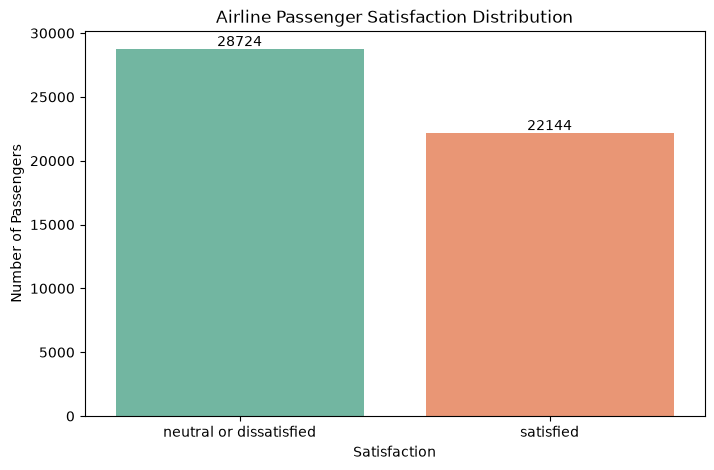

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="satisfaction",
    hue="satisfaction",
    palette="Set2",
    legend=False
)

plt.title("Airline Passenger Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.show()

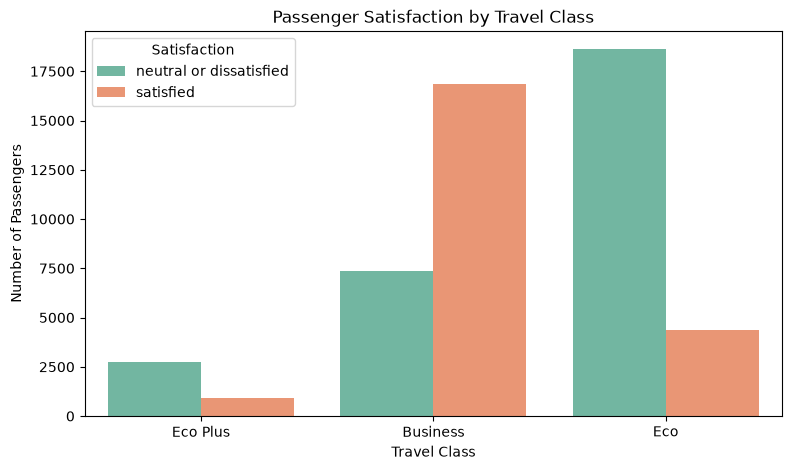

In [5]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Class",
    hue="satisfaction",
    palette="Set2"
)

plt.title("Passenger Satisfaction by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Satisfaction")
plt.show()

In [6]:
class_percentage = (
    pd.crosstab(
        df_clean["Class"],
        df_clean["satisfaction"],
        normalize="index"
    ) * 100
).round(2)

print(class_percentage)


satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                        30.41      69.59
Eco                             80.97      19.03
Eco Plus                        74.73      25.27


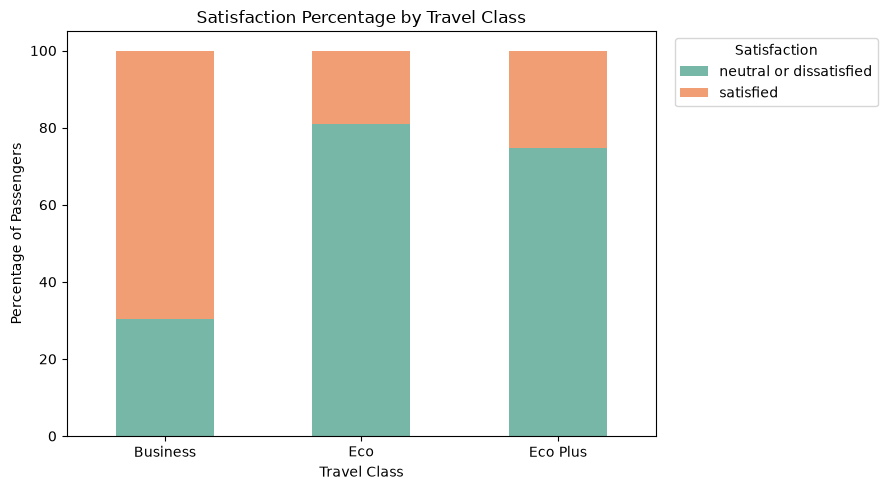

In [7]:
class_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#76b7a8", "#f29e74"]
)

plt.title("Satisfaction Percentage by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Percentage of Passengers")
plt.legend(title="Satisfaction", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
delay_by_satisfaction = (
    df_clean
    .groupby("satisfaction")[[
        "Departure Delay in Minutes",
        "Arrival Delay in Minutes"
    ]]
    .mean()
    .round(2)
)

print(delay_by_satisfaction)

                         Departure Delay in Minutes  Arrival Delay in Minutes
satisfaction                                                                 
neutral or dissatisfied                       16.42                     16.99
satisfied                                     12.82                     12.81


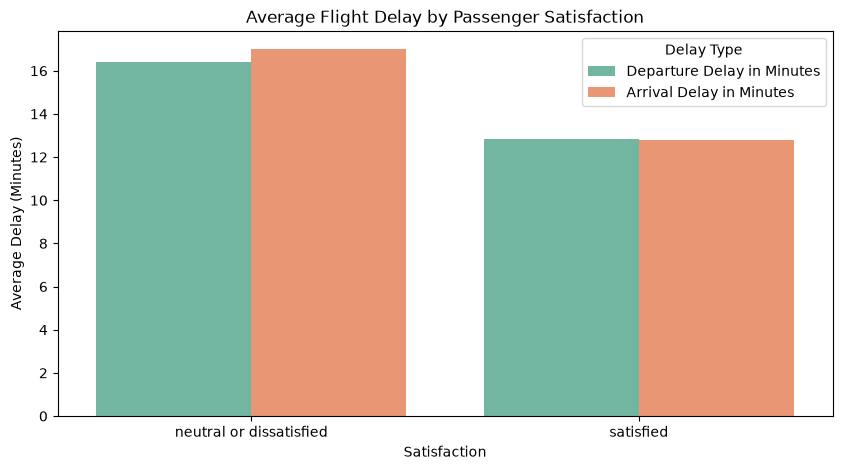

In [9]:
delay_chart = (
    delay_by_satisfaction
    .reset_index()
    .melt(
        id_vars="satisfaction",
        var_name="Delay Type",
        value_name="Average Delay (Minutes)"
    )
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=delay_chart,
    x="satisfaction",
    y="Average Delay (Minutes)",
    hue="Delay Type",
    palette="Set2"
)

plt.title("Average Flight Delay by Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Average Delay (Minutes)")
plt.legend(title="Delay Type")
plt.show()


In [10]:
service_columns = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Cleanliness"
]

service_scores = (
    df_clean
    .groupby("satisfaction")[service_columns]
    .mean()
    .T
)

service_scores["difference"] = (
    service_scores["satisfied"]
    - service_scores["neutral or dissatisfied"]
)

service_scores = service_scores.sort_values("difference", ascending=False)

print(service_scores.round(2))

satisfaction            neutral or dissatisfied  satisfied  difference
Online boarding                            2.65       4.02        1.37
Inflight entertainment                     2.90       3.95        1.05
Seat comfort                               3.04       3.96        0.92
Leg room service                           2.99       3.81        0.82
On-board service                           3.03       3.84        0.82
Cleanliness                                2.94       3.74        0.81
Inflight wifi service                      2.40       3.17        0.77
Ease of Online booking                     2.54       3.03        0.48


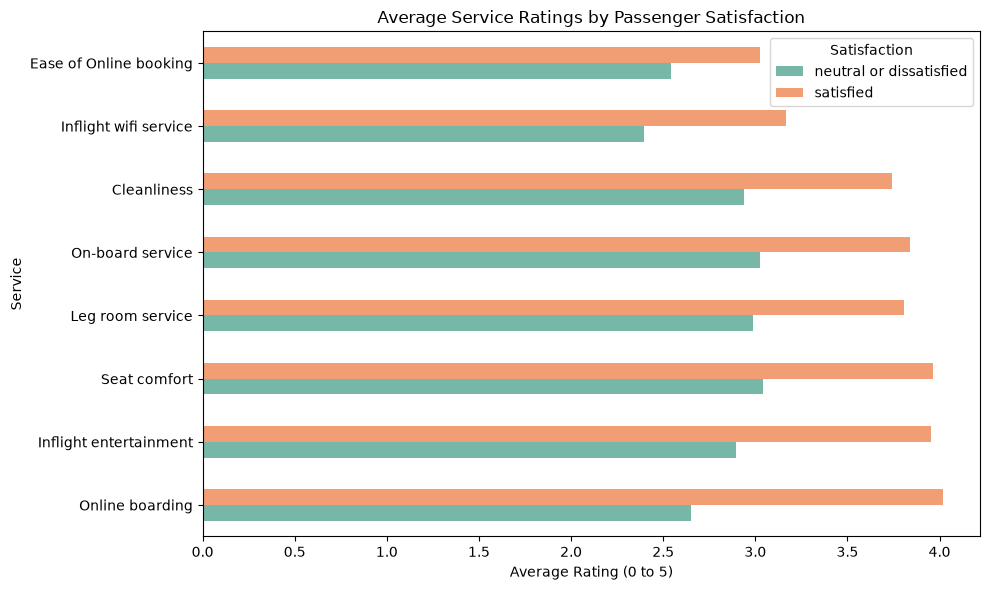

In [11]:
service_scores[
    ["neutral or dissatisfied", "satisfied"]
].plot(
    kind="barh",
    figsize=(10, 6),
    color=["#76b7a8", "#f29e74"]
)

plt.title("Average Service Ratings by Passenger Satisfaction")
plt.xlabel("Average Rating (0 to 5)")
plt.ylabel("Service")
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()


In [12]:
from sklearn.model_selection import train_test_split

# Input features and target
X = df_clean.drop(columns="satisfaction")

# Target labels: satisfied = 1, neutral/dissatisfied = 0
y = df_clean["satisfaction"].map({
    "neutral or dissatisfied": 0,
    "satisfied": 1
})

# 80% training data, 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTarget values:")
print(y.value_counts())

Training data: (40694, 22)
Testing data: (10174, 22)

Target values:
satisfaction
0    28724
1    22144
Name: count, dtype: int64


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Text/category columns
categorical_features = X.select_dtypes(include="object").columns.tolist()

# Numeric columns
numerical_features = X.select_dtypes(exclude="object").columns.tolist()

print("Categorical columns:", categorical_features)
print("\nNumber of numerical columns:", len(numerical_features))

# Convert text categories into numbers for the ML model
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)


Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']

Number of numerical columns: 18


C:\Users\Asus\AppData\Local\Temp\ipykernel_31288\3295291839.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


In [14]:
from sklearn.ensemble import RandomForestClassifier

# Preprocessing + model ko ek pipeline mein combine karo
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Model training
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Accuracy: 96.34%

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      5745
           1       0.97      0.94      0.96      4429

    accuracy                           0.96     10174
   macro avg       0.96      0.96      0.96     10174
weighted avg       0.96      0.96      0.96     10174



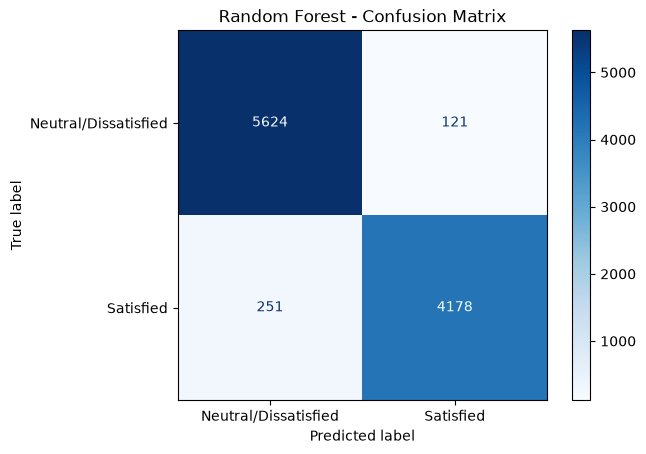

In [15]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Test-data predictions
y_pred = random_forest_model.predict(X_test)

# Accuracy and detailed metrics
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix chart
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Neutral/Dissatisfied", "Satisfied"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [16]:
# Feature importance extract karo
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.named_steps["model"].feature_importances_
})

top_features = importance_df.sort_values(
    "Importance",
    ascending=False
).head(10)

print(top_features)


                                        Feature  Importance
16                   numerical__Online boarding    0.163164
11             numerical__Inflight wifi service    0.136266
6                   categorical__Class_Business    0.075971
5   categorical__Type of Travel_Personal Travel    0.064257
4   categorical__Type of Travel_Business travel    0.053204
17                      numerical__Seat comfort    0.049917
18            numerical__Inflight entertainment    0.046523
7                        categorical__Class_Eco    0.037540
13            numerical__Ease of Online booking    0.037529
20                  numerical__Leg room service    0.031393


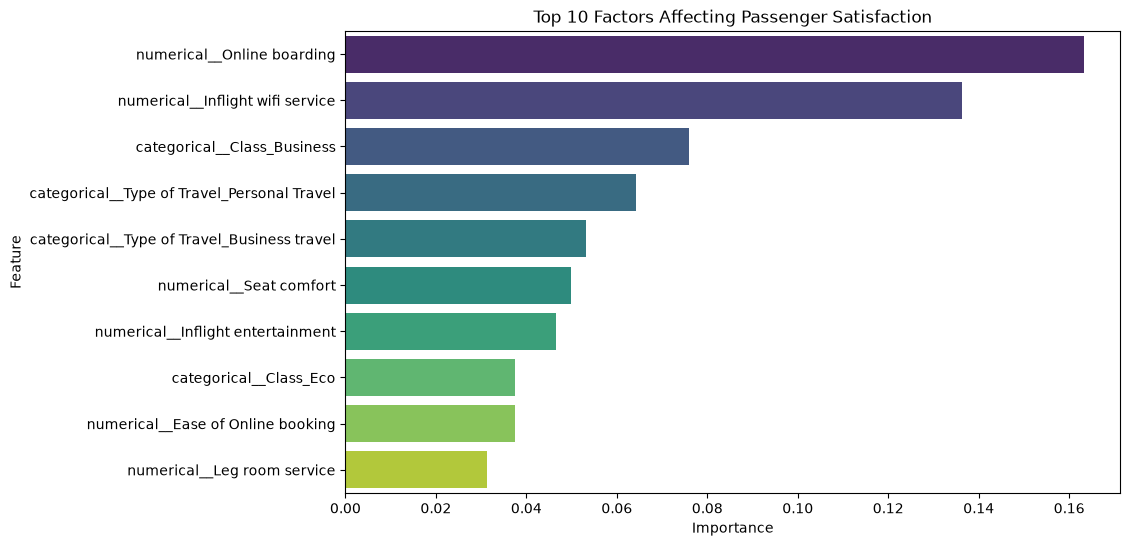

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    palette="viridis",
    hue="Feature",
    legend=False
)

plt.title("Top 10 Factors Affecting Passenger Satisfaction")
plt.show()

In [18]:
import joblib

model_path = "../models/airline_satisfaction_rf.pkl"

joblib.dump(random_forest_model, model_path)

print(f"Model saved successfully at: {model_path}")

Model saved successfully at: ../models/airline_satisfaction_rf.pkl
